In [772]:


### observations / thoughts / questions

### 1) correlation increases if I shift f?  corr(f, f) < corr(f, Tf)
### 2) does it matter if mass_f doesn't equal mass_g since we normalize to int=1?
### 3) do we expect corr(f, g) to match distance compted directly from tensors?
### 4) what is a possible explaination for why correlation would increase with heterogeneity
###    either ||g|| increases or corr decreases. (I think it's the correlation)

### 5) is there a simple function we can use to see if we are getting the correct value for f =/= g ?
###    like a Gausssian or something



In [773]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib
### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

In [804]:
# vol_a_file = 'Data/het_models/0.mrc'
# vol_b_file = 'Data/het_models/0.mrc'

vol_a_file = 'Data/het_models/5.mrc'
vol_b_file = 'Data/het_models/5.mrc'

with mrcfile.open(vol_a_file, permissive=True) as mrc:
    f = mrc.data
    dx_f = mrc.voxel_size.x  # voxels are 1x1x1
    mrc.close

with mrcfile.open(vol_b_file, permissive=True) as mrc:
    g = mrc.data
    dx_g = mrc.voxel_size.x
    mrc.close   


N = 32

sigma=5

# f = utils.generate_3d_triangle_gaussian_shape(N, sigma, rescale=False)
# g = utils.generate_3d_triangle_gaussian_shape(N, sigma, rescale=False)

f = utils.generate_centered_gaussian(N, sigma=sigma,d=3)
g = utils.generate_centered_gaussian(N, sigma=sigma,d=3)

f = utils.gaussian_3d(N, sigma=sigma)
g = utils.gaussian_3d(N, sigma=sigma)

t = time.time()
s = 1 # integer scale factor for downsample
ds = dx_f * s
# ds = 1

f = transforms.block_average_downsample(f, s) 
g = transforms.block_average_downsample(g, s) 
# g = transforms.translate_3d(g, 5, 5, 5)
print("downsample time: ", time.time() - t, '\n')


# f = np.pad(f, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size
# g = np.pad(g, pad_width=((0, 1), (0, 1), (0, 1)))  

f = signals.Signal(f, d=3, dx=ds).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=ds).preprocess_signals()[0]


print(f.shape)
print(np.amin(f), np.amax(f), np.sum(f))
print(np.amin(g), np.amax(g), np.sum(g))
print('\n')

downsample time:  0.003155946731567383 

(32, 32, 32)
0.0 0.000507055565134866 1.0
0.0 0.000507055565134866 1.0




/Users/oscarmi/miniconda3/envs/sw3/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/oscarmi/miniconda3/envs/sw3/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


In [805]:
np.linalg.norm(f)

0.013579000667389091

In [806]:
importlib.reload(alignments)
d = 3            # dimensons
M = f.shape[0]   # grid size LxLxL
N = f.shape[0]
max_l = M//2

z = np.linspace(-1, 1, N, endpoint=False)
thetas = np.linspace(0, np.pi, N, endpoint=True)
phis = np.linspace(0, 2*np.pi, N, endpoint=False)


dVsphere = (z[1]-z[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 
# dVsphere = (z[1]-z[0])**3
# dVsphere = (2/(f.shape[0]))**3


sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]
# sinthetas = np.ones(M)

f_t = transforms.Transform(f, d=3).inverse_cdf_transform()[0]
g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

# import matplotlib.pyplot as plt
# plt.plot(f_t[0,:,0]*2*np.sqrt(np.pi))

t = time.time()
c = alignments.fast_rotational_correlation(f_t, g_t, fle)
print("compute correlation: ", time.time() - t, '\n')

print(dVsphere)

correlation R=0:  5.1629680851616495
all correlation:  5.160306593329157
compute correlation:  1.1295781135559082 

0.001243649748121139


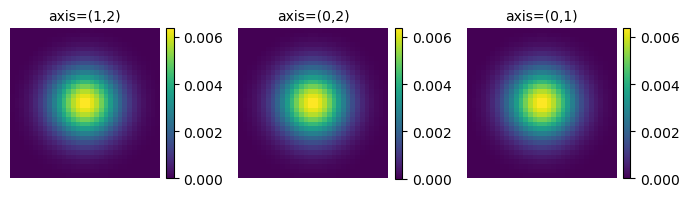

True

In [807]:
plots.orthogonal_2D_projection_plot(f)

np.allclose(f,g)

In [808]:
# f_t_norm = np.linalg.norm(f_t * sinthetas)
# g_t_norm = np.linalg.norm(g_t * sinthetas)


f_t_norm = np.sqrt(np.sum(f_t**2 * sinthetas))
g_t_norm = np.sqrt(np.sum(g_t**2 * sinthetas))



print(f_t_norm**2 * dVsphere, g_t_norm**2 * dVsphere/np.amax(c))

7.159393559951899 1.3866818962990082


In [809]:
# np.sum((f_t * g_t) * sinthetas**2) * dVsphere

np.sum(f_t * g_t * sinthetas) * dVsphere

7.159393559951899

In [810]:
np.amax(c), np.amin(c)

(5.162967497491674, 5.157645794010177)

In [788]:
2 * np.amax(c) 

9.952598772738572

In [789]:
f_t_norm**2 * dVsphere

6.752894179093768

In [790]:
# ( (f_t_norm**2 + g_t_norm**2) * dVsphere*4.288/6.681 - 2*np.amax(c) ) 

( (f_t_norm**2 + g_t_norm**2) * dVsphere - 2*np.amax(c) ) 

3.5531895854489637

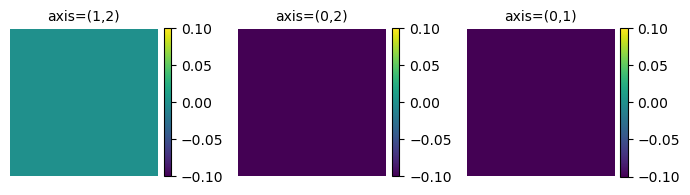

In [791]:
plots.orthogonal_2D_projection_plot(f - g)

In [792]:
### compute the distance from tensors, the expanded terms 
### and then compare to the correlation from FRC
### skip the 1/4pi average?

sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]

### EV: if I use this they match, so not propogating the sin(theta) correctly?
# sinthetas = np.ones(M)



dS = (thetas[1]-thetas[0])*(phis[1]-phis[0])

d_total = np.sum((f_t*sinthetas - g_t*sinthetas)**2) 


### EV: probably should be the mean ?
# d_slices = np.mean((f_t*sinthetas - g_t*sinthetas)**2, axis=1)
# d_total = np.mean(d_slices)
# d_total = np.mean((f_t*sinthetas - g_t*sinthetas)**2)  # same thing


d_total * dS 

0.0

In [793]:
# np.linalg.norm(f_t * sinthetas)**2 * dS

In [794]:
# dS * ( np.linalg.norm(f_t * sinthetas)**2 + np.linalg.norm(g_t * sinthetas)**2 - 2*np.sum( (f_t * g_t)*sinthetas ) )


dS * ( np.linalg.norm(f_t * sinthetas)**2 + np.linalg.norm(g_t * sinthetas)**2 - 2*np.sum( (f_t * g_t)*sinthetas**2 ) ) 


0.0

In [795]:
# np.mean(f_t * g_t) * dS

In [796]:
np.allclose(np.linalg.norm(f_t * sinthetas)**2 , np.sum(f_t**2 * sinthetas**2))

True

In [758]:
np.linalg.norm(f_t*sinthetas - g_t*sinthetas)**2 * dS

0.0

In [759]:
sinthetas.shape


(1, 1, 32)

In [760]:
a = np.random.randn(2,2)
b = np.random.randn(2)[np.newaxis,:]

In [761]:
a

array([[-1.00504778,  1.40362659],
       [-0.53777826,  0.17570638]])

In [762]:
b

array([[ 0.39008729, -1.56684411]])

In [763]:
a*b

array([[-0.39205637, -2.19926405],
       [-0.20978046, -0.27530451]])

(4.500645996577754e-08+0j)


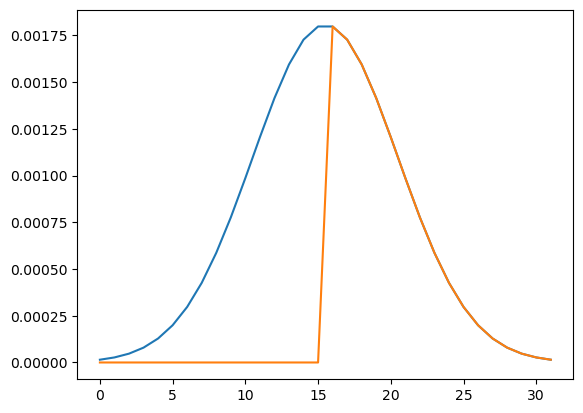

In [766]:

lmax = fle.lmax+1


# sigma = 0.2
# p = np.array(np.meshgrid(*[z for _ in range(d)]))
# f = np.exp(-( np.sum(p**2, axis=0) ) / (2*sigma**2))
# g = f

# f2 = np.exp(-( z**2 ) / (2*sigma**2))
# g2 = f2

fhat = np.zeros((len(z), lmax, 2*lmax+1))
ghat = np.zeros((len(z), lmax, 2*lmax+1))
fhat[:,0,0] = f[M//2, M//2, :]*(2*np.sqrt(np.pi)) 
ghat[:,0,0] = g[M//2, M//2, :]*(2*np.sqrt(np.pi)) 
# fhat[:,0,0] = f2*(2*np.sqrt(np.pi)) 
# ghat[:,0,0] = g2*(2*np.sqrt(np.pi)) 
plt.figure()
plt.plot(fhat[:,0,0])
plt.plot(fhat[:,0,0]*(z>z[M//2-1]))
#these are now in order radius, l, m, where for fixed radius and l, the m index varies like
#m=0,-1,1,-2,2,-3,3, ...


Ilm = np.zeros((lmax,2*lmax+1,2*lmax+1),dtype=np.complex128)
# we need to remember to multiply by r^2, which cancels out the 1/abs(z) above...
for m1 in range(-lmax, lmax+1):
    m1ind = 2*np.abs(m1) - (m1 < 0)
    for m2 in range(-lmax, lmax+1):
        m2ind = 2*np.abs(m2) - (m2 < 0)
        #wfhat, ghat have a different ordering. m1ind and m2ind fix this
        for i in range(fhat.shape[0]):
            #should this actually only be for positive z? also need to divide by delta z...
            #we can use better quadrature here to get increased accuracy
            # if z[i] > 0:
            Ilm[:,m1+lmax,m2+lmax] += fhat[i,:,m1ind]*np.conj(ghat[i,:,m2ind])*(z[1]-z[0])*z[i]**2/2
print(np.sum(Ilm.flatten()))
# tmp2 = np.sum(Ilm[:,0,0])
tmp2 = np.sum(Ilm.flatten())

# tmp = 0
# for i in range(fhat.shape[0]):
#     #should this actually only be for positive z? also need to divide by delta z...
#     #we can use better quadrature here to get increased accuracy
#     # if z[i] > 0:
#     tmp += (fhat[i,0,0]**2)*(z[1]-z[0])*z[i]**2/2
  
# import scipy.integrate as integrate

# tmp2 = integrate.simpson(fhat[:,0,0]**2*z**2, x=z)/2 #/2 because you are doing the integral from -1 to so double-counting
# print('correlation R=0: ', tmp.real, tmp2)


In [741]:
dz3 = (z[1]-z[0])**3
# dz3 = (2/(N))**3
f_t_norm = np.sqrt(np.sum(f**2)*dz3)
g_t_norm = np.sqrt(np.sum(g**2)*dz3)


print(f_t_norm**2, g_t_norm**2)
print(g_t_norm**2/tmp2)

4.1198966718014265e-08 4.1198966718014265e-08
(0.9803992326773808+0j)


In [732]:
1.2655531915400907e-07/2.312319209343103e-08/np.pi/np.sqrt(np.pi)

0.9828965423401502

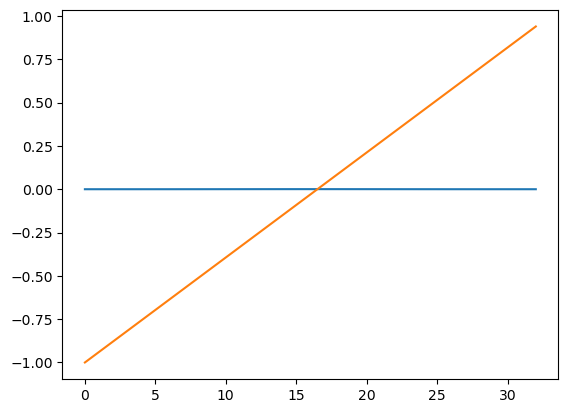

In [733]:
plt.plot(f[M//2, M//2, :])
plt.plot(z)